In [2]:
import pandas as pd
import ast
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')

df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else x
)

<Axes: xlabel='skill_count', ylabel='skill_pay'>

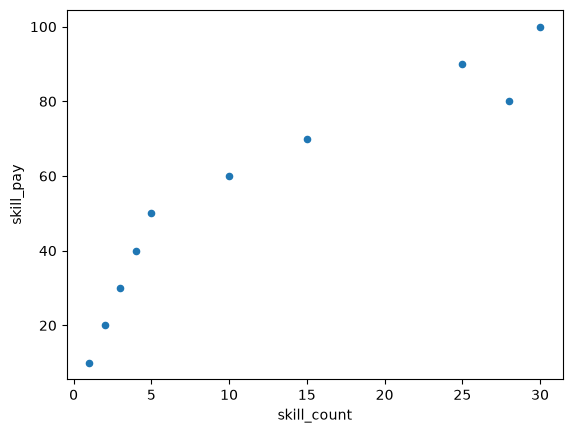

In [3]:
data = {
    'job_skills': ['python', 'sql', 'java', 'javascript', 'c++', 'html', 'css', 'r', 'php', 'c#'],
     'skill_count': [30, 25, 28, 15, 10, 5, 4, 3, 2, 1],
     'skill_pay': [100, 90, 80, 70, 60, 50  , 40, 30, 20, 10]
}

df = pd.DataFrame(data)

df.plot(kind='scatter', x='skill_count', y='skill_pay')

In [4]:
df = df[df['job_title_short'] == 'Data Analyst']

KeyError: 'job_title_short'

In [ ]:
print(df.columns.tolist())

['job_skills', 'skill_count', 'skill_pay']


In [7]:
from datasets import load_dataset

dataset = load_dataset('lukebarousse/data_jobs')

df = dataset['train'].to_pandas()

In [8]:
df = df[df['job_title_short'] == 'Data Analyst']

In [16]:
df_exploded = df.explode('job_skills')

skill_stats = df_exploded.groupby('job_skills').agg(
    skill_count=('job_skills', 'count'),
    median_salary=('salary_year_avg', 'median')
)

skills_stats = skill_stats.sort_values(by='skill_count', ascending=False).head(10)

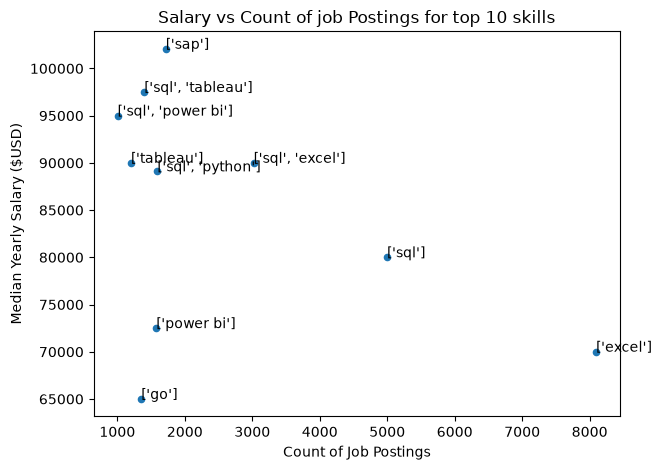

In [18]:
skills_stats.plot(kind='scatter', x='skill_count', y='median_salary')
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary ($USD)')
plt.title('Salary vs Count of job Postings for top 10 skills')
plt.tight_layout()

for i, txt in enumerate(skills_stats.index):
    plt.text(skills_stats['skill_count'].iloc[i], skills_stats['median_salary'].iloc[i], txt)
plt.show()